# One-step evaluation

Performance用データとcheckpointを確認してから1-step評価を実行し、保存済みmetricsとPNGを可視化します。YAMLはNotebookから変更しません。


## 1. 使用する設定


In [2]:
from pathlib import Path
import csv, subprocess, sys
import matplotlib.pyplot as plt
import yaml
from IPython.display import Image, Markdown, display

def find_project_root(start):
    start = Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "configs").is_dir() and (candidate / "performance").is_dir():
            return candidate
    raise FileNotFoundError("FNOV2リポジトリ内からNotebookを開いてください。")

def resolve(value, config_path):
    path = Path(value)
    return path.resolve() if path.is_absolute() else (config_path.parent / path).resolve()

def status(ok, label, detail=""):
    mark = "✅" if ok else "❌"
    print(f"{mark} {label}" + (f": {detail}" if detail else ""))
    return ok

ROOT = find_project_root(Path.cwd())
print("project:", ROOT)
################################
EXPERIMENT_ID = "ex008_baseline"
################################
print("experiment:", EXPERIMENT_ID)
TEST_YAML = ROOT / "performance/configs/test.yaml"
test_cfg = yaml.safe_load(TEST_YAML.read_text(encoding="utf-8"))
loader_path = resolve(test_cfg["test_dataloader_config"], TEST_YAML)
loader_cfg = yaml.safe_load(loader_path.read_text(encoding="utf-8"))
kind = loader_cfg["evaluation"]["type"]
data_dir = resolve(loader_cfg["data"]["directory"], loader_path)
checkpoint = resolve(test_cfg["checkpoint"], TEST_YAML)
result_dir = resolve(test_cfg["output"]["root_directory"], TEST_YAML) / kind / "one_step"


project: /workspace/FNOV2
experiment: ex008_baseline


## 2. 設定の可視化


In [3]:
summary={
 "evaluation":kind, "data directory":str(data_dir), "test Re":loader_cfg["test_re"],
 "checkpoint":str(checkpoint), "device":test_cfg["device"], "output":str(result_dir),
 "dataset config":str(resolve(loader_cfg["dataset_config"],loader_path)),
}
print(yaml.safe_dump(summary,allow_unicode=True,sort_keys=False))
display(Markdown("### test.yaml")); print(TEST_YAML.read_text(encoding="utf-8"))
display(Markdown("### test_dataloader.yaml")); print(loader_path.read_text(encoding="utf-8"))


evaluation: interpolation
data directory: /workspace/FNOV2/performance/data/interpolation/processed/pairs
test Re:
- 35
- 85
- 135
- 185
- 235
checkpoint: /workspace/FNOV2/outputs/training/ex008/best.pt
device: auto
output: /workspace/FNOV2/performance/results/ex008_baseline/interpolation/one_step
dataset config: /workspace/FNOV2/configs/dataset.yaml



### test.yaml

test_dataloader_config: test_dataloader.yaml
model_config: ../../configs/model.yaml
###モデルの切り替え
checkpoint: ../../outputs/training/ex008/best.pt
device: auto

# evaluation.typeから結果の interpolation/extrapolation を導出する。
output:
  root_directory: ../results/ex008_baseline
  metrics_json: metrics.json
  metrics_csv: metrics.csv
  interpolation_plot: interpolation_relative_l2.png
  extrapolation_plot: extrapolation_relative_l2.png



### test_dataloader.yaml

# interpolation / extrapolationはこのconfigだけで切り替える。
evaluation:
  type: interpolation

data:
  directory: ../data/interpolation/processed/pairs
  file_pattern: "pairs_case*_Re*.pt"

test_re:
  - 35
  - 85
  - 135
  - 185
  - 235

# channel構成とtrain統計量、および共通loader設定の正本。
dataset_config: ../../configs/dataset.yaml
dataloader_config: ../../configs/dataloader.yaml



## 3. 実行前チェック


In [4]:
files=sorted(data_dir.glob(loader_cfg["data"]["file_pattern"]))
expected={float(v) for v in loader_cfg["test_re"]}
found=set()
for path in files:
    try: found.add(float(path.stem.rsplit("_Re",1)[1]))
    except (IndexError,ValueError): pass
performance_root=(ROOT/"performance/data"/kind).resolve()
checks=[
 status(TEST_YAML.is_file(),"test config",TEST_YAML),
 status(loader_path.is_file(),"test dataloader config",loader_path),
 status(checkpoint.is_file(),"checkpoint",checkpoint),
 status(data_dir.is_dir(),"performance data directory",data_dir),
 status(data_dir.is_relative_to(performance_root),"data isolation",performance_root),
 status(bool(files),"pair files",f"{len(files)} files"),
 status(found==expected,"Re filenames",f"expected={sorted(expected)}, found={sorted(found)}"),
 status(result_dir.parents[1].name==EXPERIMENT_ID,"experiment result root",result_dir.parents[1]),
]
PRECHECK_OK=all(checks)
print("\n実行可能" if PRECHECK_OK else "\n設定またはデータを修正してください。")


✅ test config: /workspace/FNOV2/performance/configs/test.yaml
✅ test dataloader config: /workspace/FNOV2/performance/configs/test_dataloader.yaml
✅ checkpoint: /workspace/FNOV2/outputs/training/ex008/best.pt
✅ performance data directory: /workspace/FNOV2/performance/data/interpolation/processed/pairs
✅ data isolation: /workspace/FNOV2/performance/data/interpolation
✅ pair files: 5 files
✅ Re filenames: expected=[35.0, 85.0, 135.0, 185.0, 235.0], found=[35.0, 85.0, 135.0, 185.0, 235.0]
✅ experiment result root: /workspace/FNOV2/performance/results/ex008_baseline

実行可能


## 4. 1-step評価の実行


In [5]:
RUN_ONE_STEP = True
if RUN_ONE_STEP:
    if not PRECHECK_OK: raise RuntimeError("事前チェックが失敗しています。")
    subprocess.run([sys.executable,str(ROOT/"performance/src/test.py"),"--config",str(TEST_YAML)],cwd=ROOT,check=True)
else: print("未実行。確認後にRUN_ONE_STEP=Trueへ変更してください。")


=== One-step Test Summary ===
evaluation       : interpolation
device           : cpu
checkpoint epoch : 298
test Re          : [35.0, 85.0, 135.0, 185.0, 235.0]
test files       : 5
test samples     : 500
valid-region MSE : 1.144056e-06 (standardized)
valid-region L2  : 1.076410e-03 (standardized)
metrics JSON     : /workspace/FNOV2/performance/results/ex008_baseline/interpolation/one_step/metrics.json
metrics CSV      : /workspace/FNOV2/performance/results/ex008_baseline/interpolation/one_step/metrics.csv
metric plot PNG  : /workspace/FNOV2/performance/results/ex008_baseline/interpolation/one_step/interpolation_relative_l2.png


## 5. Metrics


In [13]:
metrics_csv=result_dir/test_cfg["output"]["metrics_csv"]
if not metrics_csv.exists(): print("結果がありません:",metrics_csv)
else:
 with metrics_csv.open(encoding="utf-8",newline="") as f: rows=list(csv.DictReader(f))
 selected=[r for r in rows if r["scale"]=="physical" and r["region"]=="valid_region" and r["Re"]!="all"]
 print("Re      channel       MSE             Relative L2")
 for r in selected: print(f'{r["Re"]:>5}   {r["channel"]:>7}   {float(r["mse"]):.6e}   {float(r["relative_l2"]):.6f}')


Re      channel       MSE             Relative L2
  260       all   2.148578e-08   0.005804
  260         u   5.113028e-08   0.005400
  260         v   1.332103e-08   0.009115
  260         p   6.042563e-12   0.006052
  270       all   2.833609e-08   0.006414
  270         u   6.726554e-08   0.005966
  270         v   1.773347e-08   0.010035
  270         p   9.278385e-12   0.006911
  280       all   3.601931e-08   0.006970
  280         u   8.488339e-08   0.006464
  280         v   2.315927e-08   0.010961
  280         p   1.525674e-11   0.008229
  290       all   4.734893e-08   0.007711
  290         u   1.107384e-07   0.007130
  290         v   3.128298e-08   0.012191
  290         p   2.545139e-11   0.009921
  300       all   6.341114e-08   0.008622
  300         u   1.447672e-07   0.007884
  300         v   4.542090e-08   0.014073
  300         p   4.536208e-11   0.012344


## 6. 保存済みグラフ


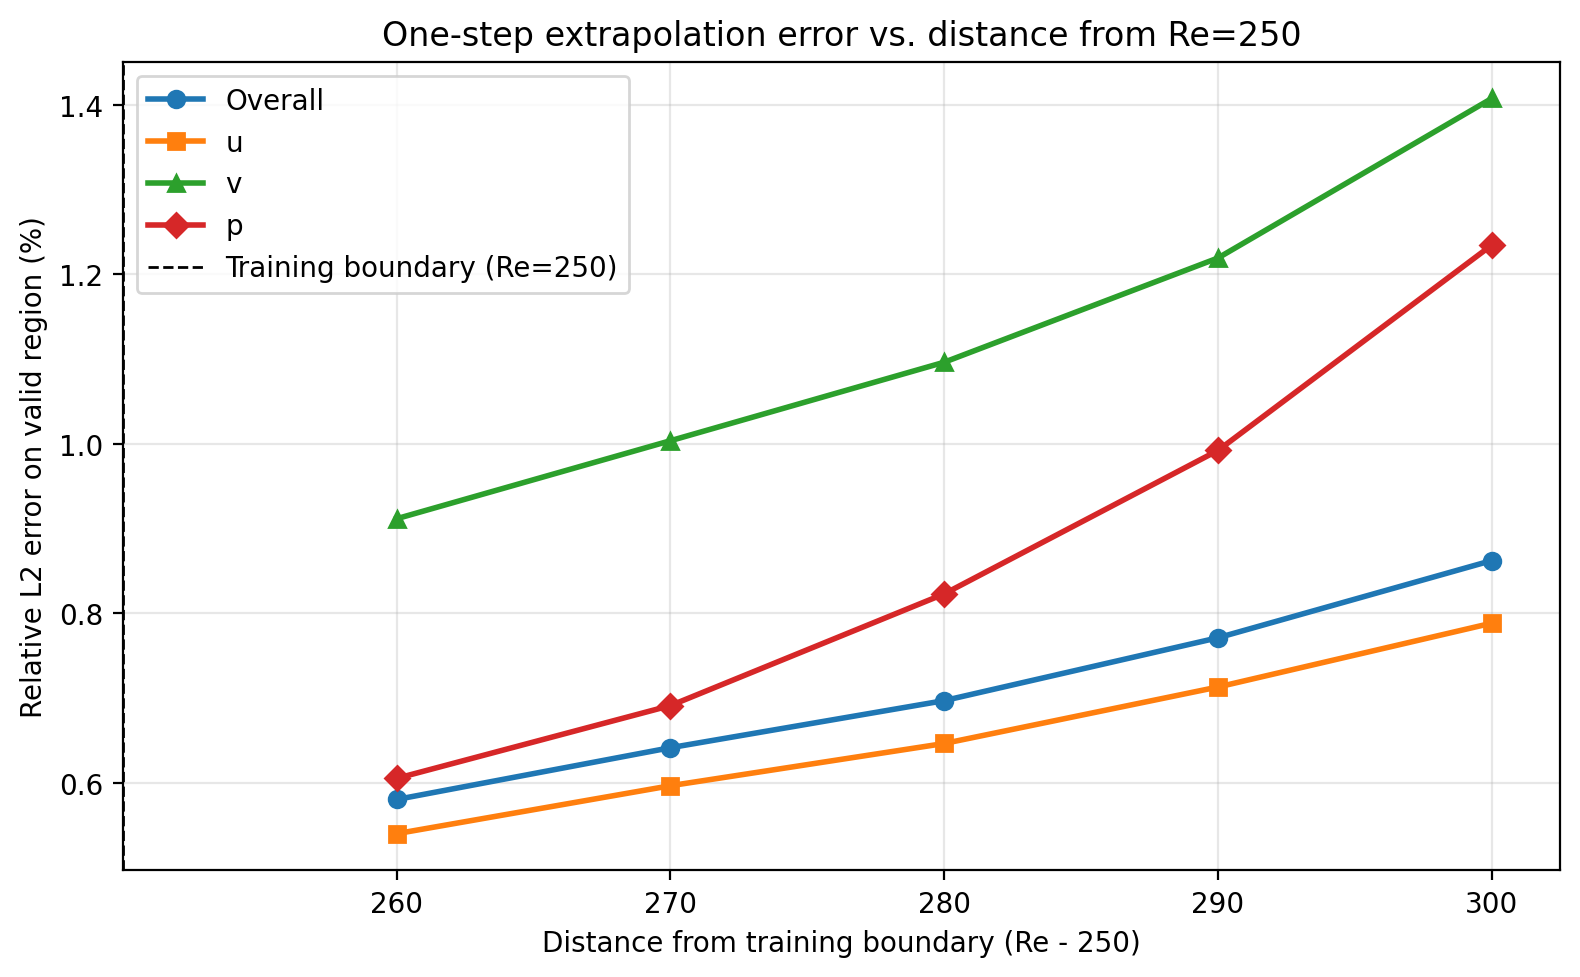

In [14]:
plot_key="interpolation_plot" if kind=="interpolation" else "extrapolation_plot"
plot_path=result_dir/test_cfg["output"][plot_key]
if plot_path.exists(): display(Image(filename=str(plot_path)))
else: print("PNGがありません:",plot_path)


## 7. 流れ場の比較（物理スケール）

`VIS_RE` を設定内のReから選んで実行します。既存のtest loader・モデル・学習統計量を使って、選んだReの全サンプルを再推論し、物理スケールの結果を保存します。
次の描画セルだけ再実行すれば再推論は不要です。等間隔5点＋有効領域のRelative L2最大点を表示します。
正解と予測は各行で同じ色範囲、絶対誤差は0始まり、mask無効領域は灰色です。


In [15]:
import importlib.util
import numpy as np
import torch
from torch.utils.data import DataLoader

VIS_RE = float(loader_cfg["test_re"][0])  # この値を変更してReを選択
N_REPRESENTATIVE = 5
SAVE_FIELD_PNG = True

# 同名のtestモジュールとの衝突を避け、既存の評価実装を読み込む。
spec = importlib.util.spec_from_file_location("one_step_evaluation", ROOT / "performance/src/test.py")
one_step = importlib.util.module_from_spec(spec)
spec.loader.exec_module(one_step)

if VIS_RE not in set(map(float, loader_cfg["test_re"])):
    raise ValueError(f"VIS_RE must be one of {loader_cfg['test_re']}")
field_loader = one_step.create_test_dataloader(loader_path)
field_dataset = field_loader.dataset.select_reynolds([VIS_RE])
field_batches = DataLoader(field_dataset, batch_size=field_loader.batch_size, shuffle=False)
field_device = one_step.select_device(test_cfg["device"])
field_model = one_step.build_model(resolve(test_cfg["model_config"], TEST_YAML)).to(field_device)
field_checkpoint = one_step.load_checkpoint(checkpoint, field_model, field_device)
field_model.eval()
mask_index = field_dataset.input_channels.index("mask")
field_predictions, field_targets, field_masks = [], [], []
with torch.inference_mode():
    for x_batch, target_batch in field_batches:
        x_batch, target_batch = x_batch.to(field_device), target_batch.to(field_device)
        prediction_batch = field_model(x_batch)
        if prediction_batch.shape != target_batch.shape:
            raise ValueError("Prediction/target shape mismatch")
        mask_batch = x_batch[:, mask_index].bool()
        pred_phys = field_dataset.inverse_transform_output(prediction_batch, mask_batch)
        true_phys = field_dataset.inverse_transform_output(target_batch, mask_batch)
        if not (torch.isfinite(pred_phys).all() and torch.isfinite(true_phys).all()):
            raise ValueError("Prediction/target contains NaN or Inf")
        if not mask_batch.flatten(1).any(1).all():
            raise ValueError("Sample contains no mask-valid elements")
        field_predictions.append(pred_phys.cpu())
        field_targets.append(true_phys.cpu())
        field_masks.append(mask_batch.cpu())

# test loaderはReごとに1ファイルであることを検証済み。
source_package = torch.load(field_dataset.files[0], map_location="cpu", weights_only=False)
field_result = {
    "prediction": torch.cat(field_predictions),
    "ground_truth": torch.cat(field_targets),
    "mask": torch.cat(field_masks),
    "Re": VIS_RE,
    "times": source_package.get("times"),
    "meta": {**source_package["meta"], "scale": "physical",
             "output_channels": list(field_dataset.output_channels),
             "checkpoint": str(checkpoint), "checkpoint_epoch": field_checkpoint.get("epoch"),
             "source_file": str(field_dataset.files[0])},
}
result_dir.mkdir(parents=True, exist_ok=True)
field_result_path = result_dir / f"1step_Re{VIS_RE:g}.pt"
torch.save(field_result, field_result_path)
print("saved:", field_result_path)
del source_package, field_model, field_checkpoint, field_predictions, field_targets, field_masks


saved: /workspace/FNOV2/performance/results/ex004_baseline/extrapolation/one_step/1step_Re260.pt


Maximum physical/valid-region Relative L2: sample=43, error=0.00687309
Visualization samples: [0, 25, 43, 50, 74, 99]


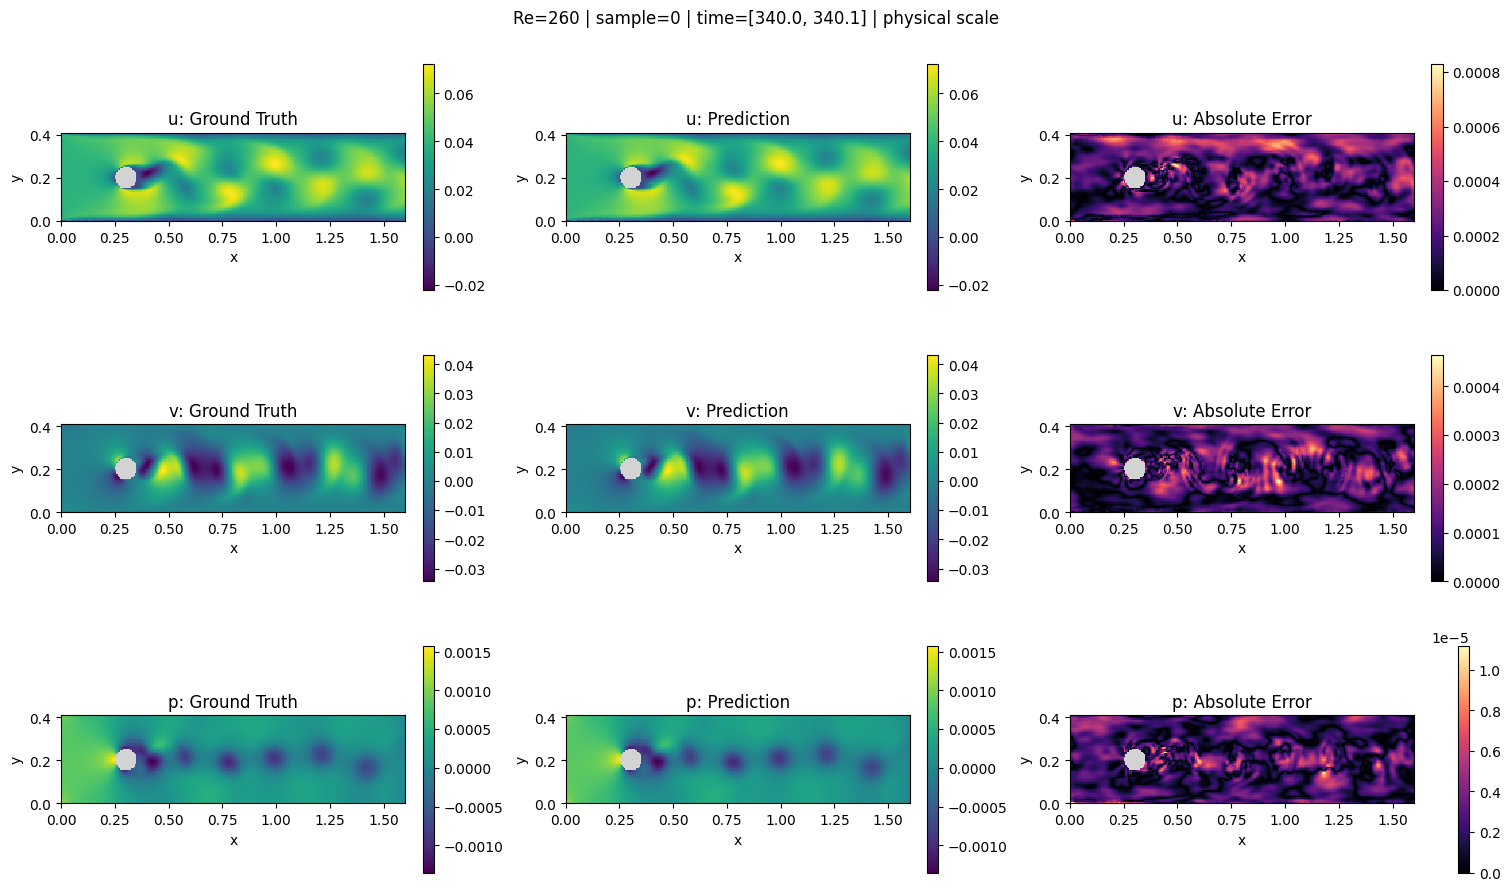

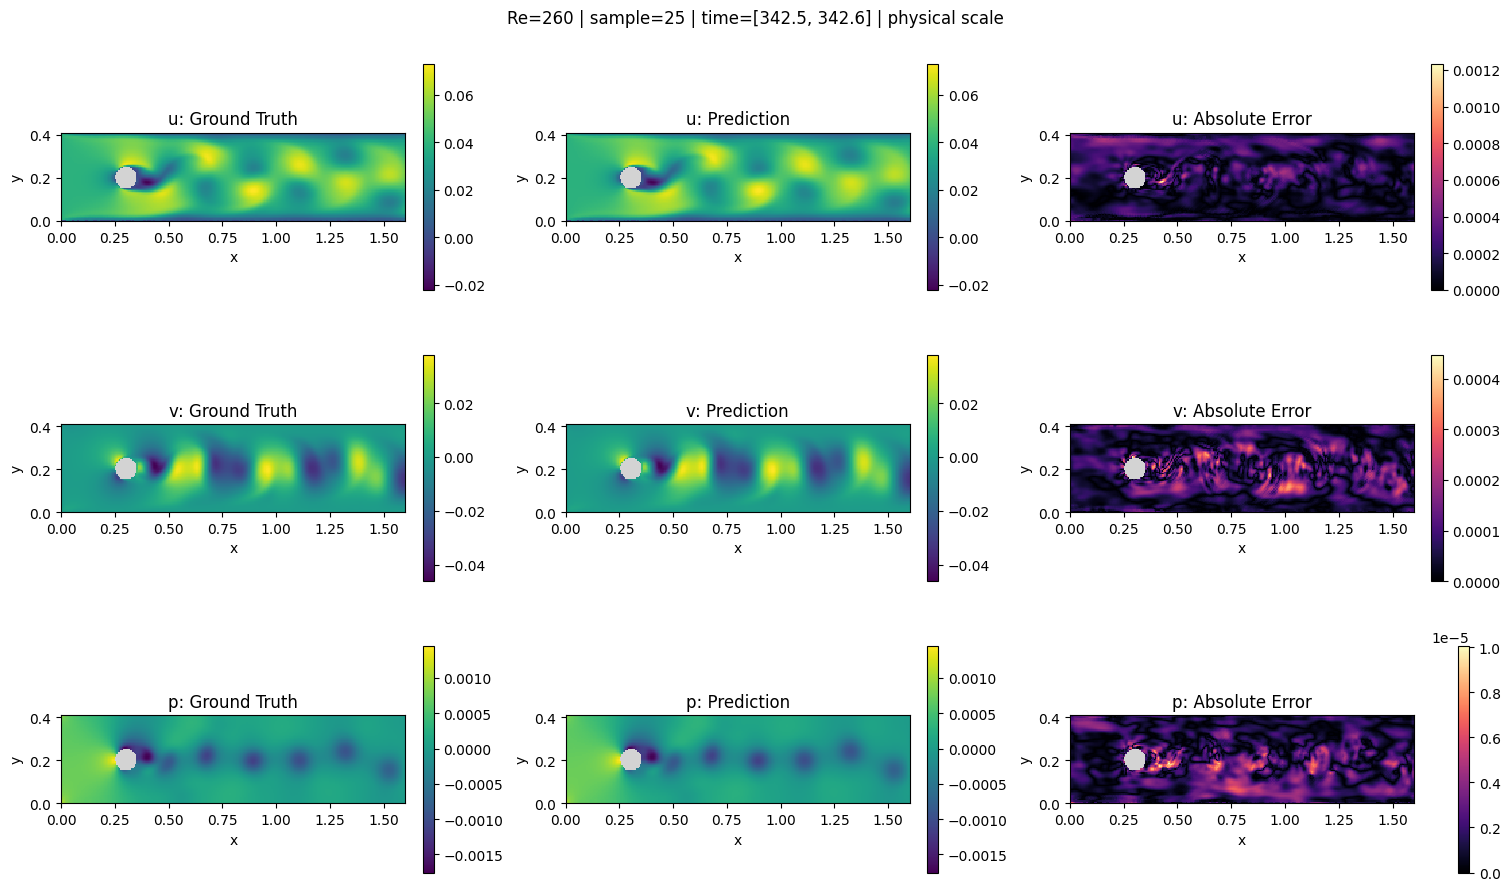

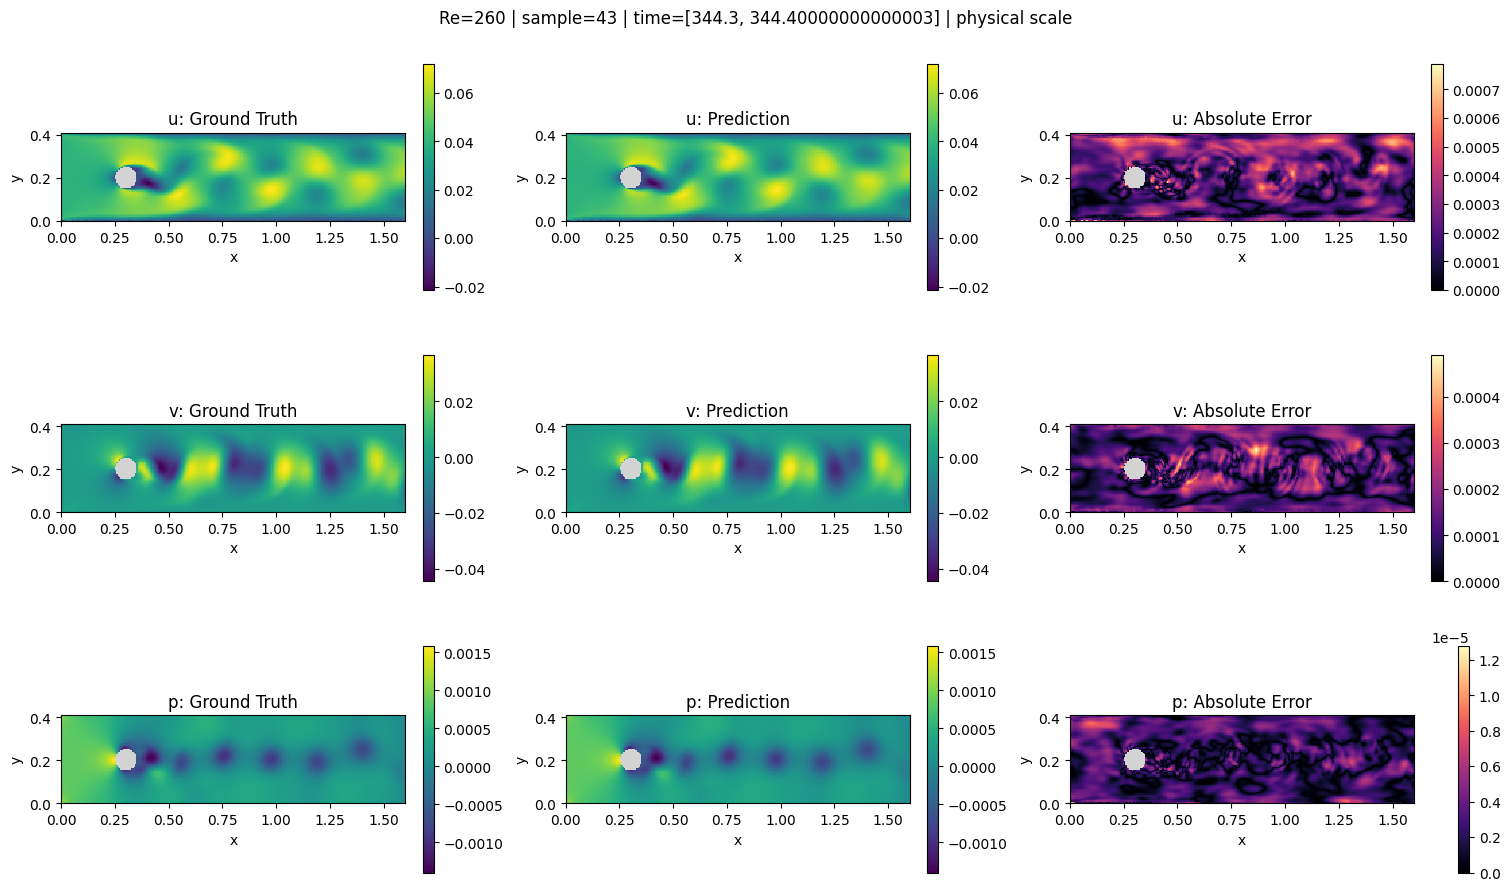

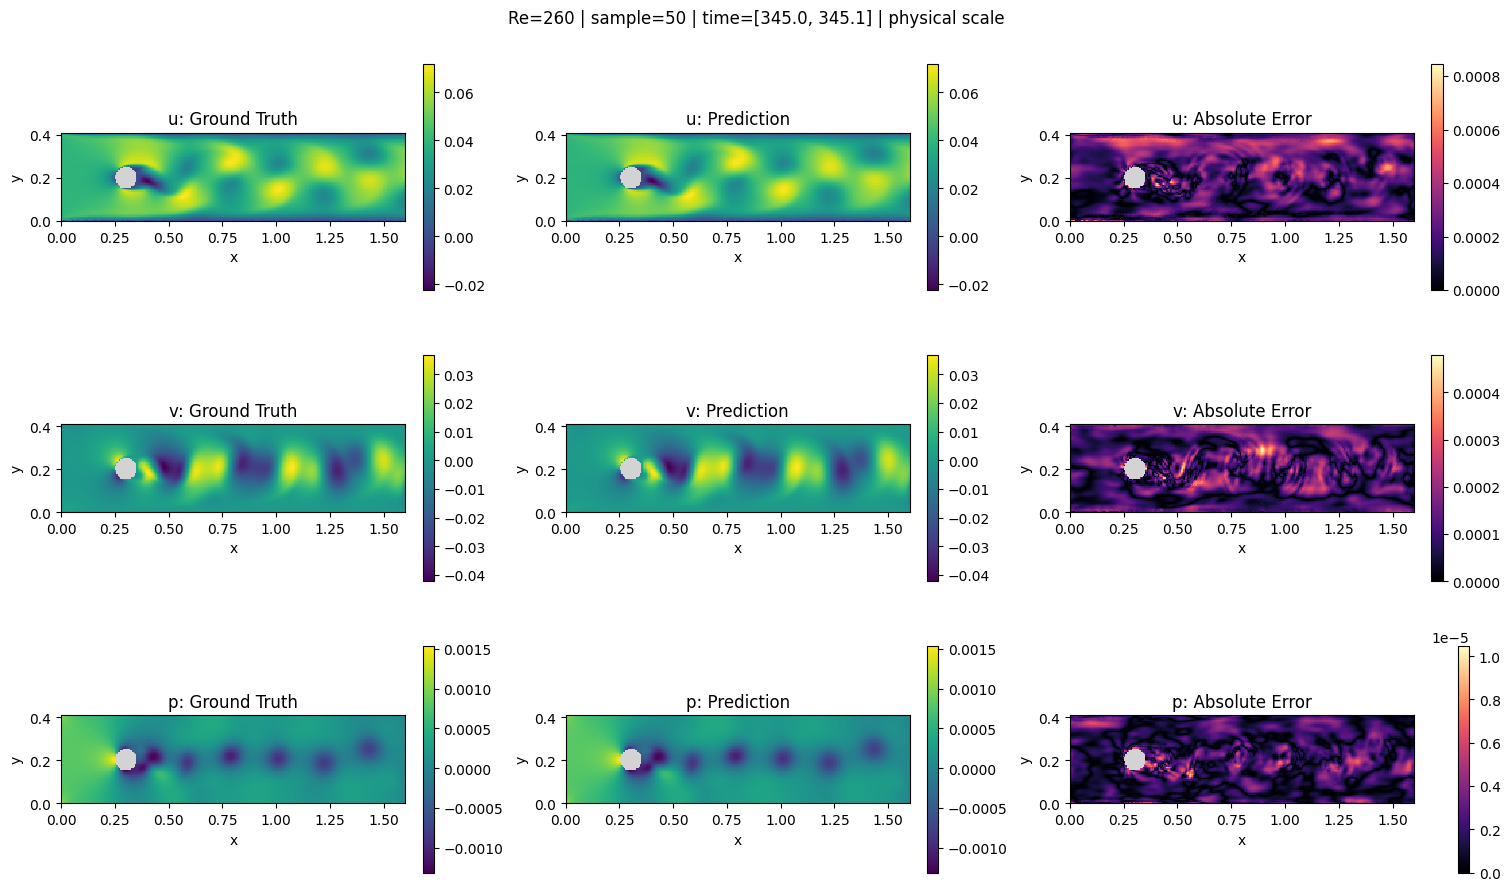

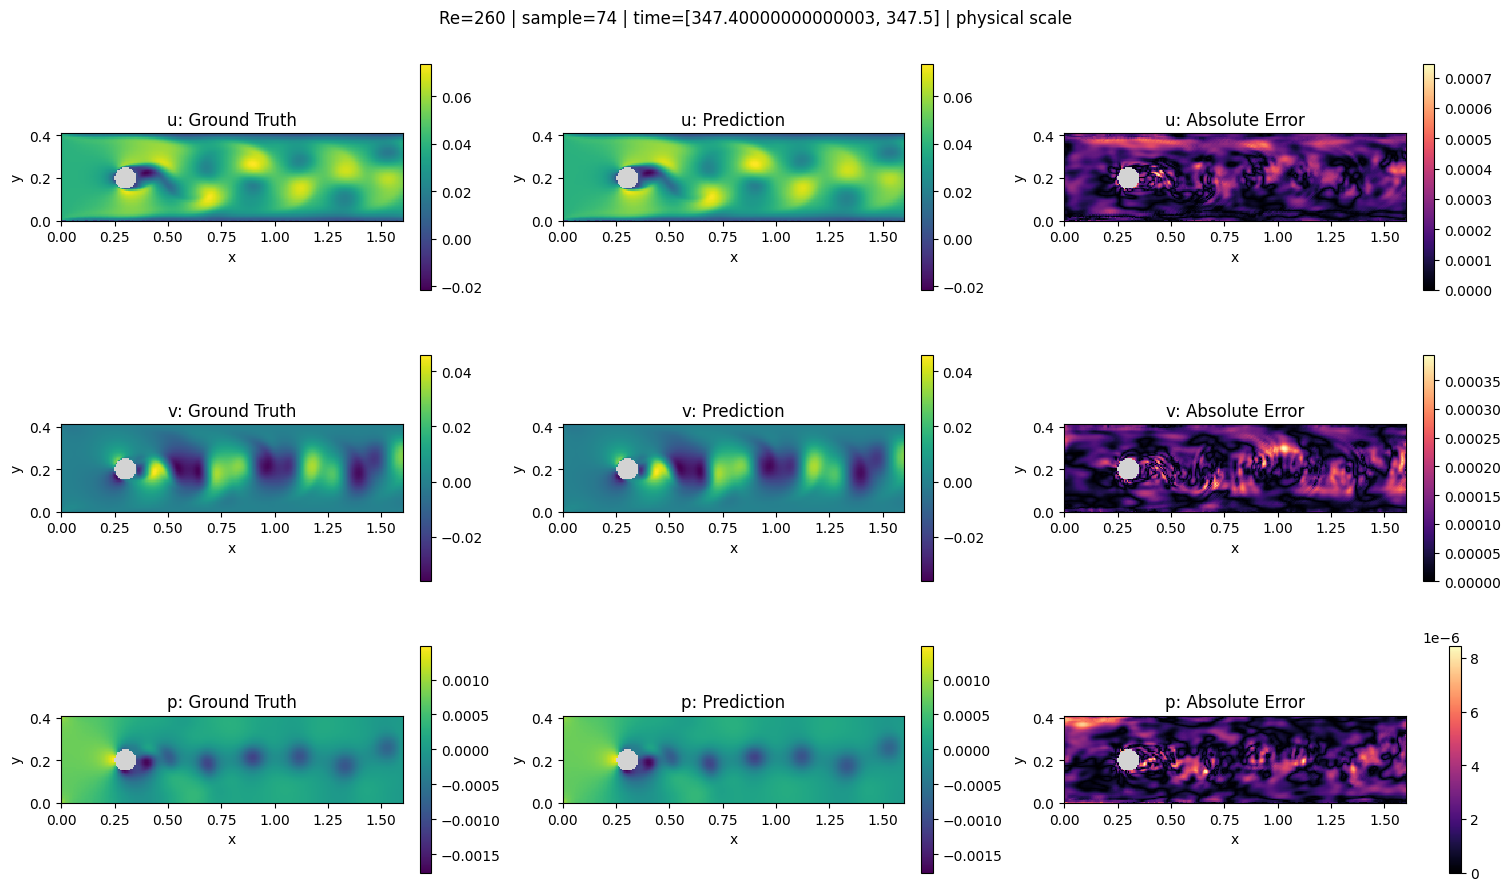

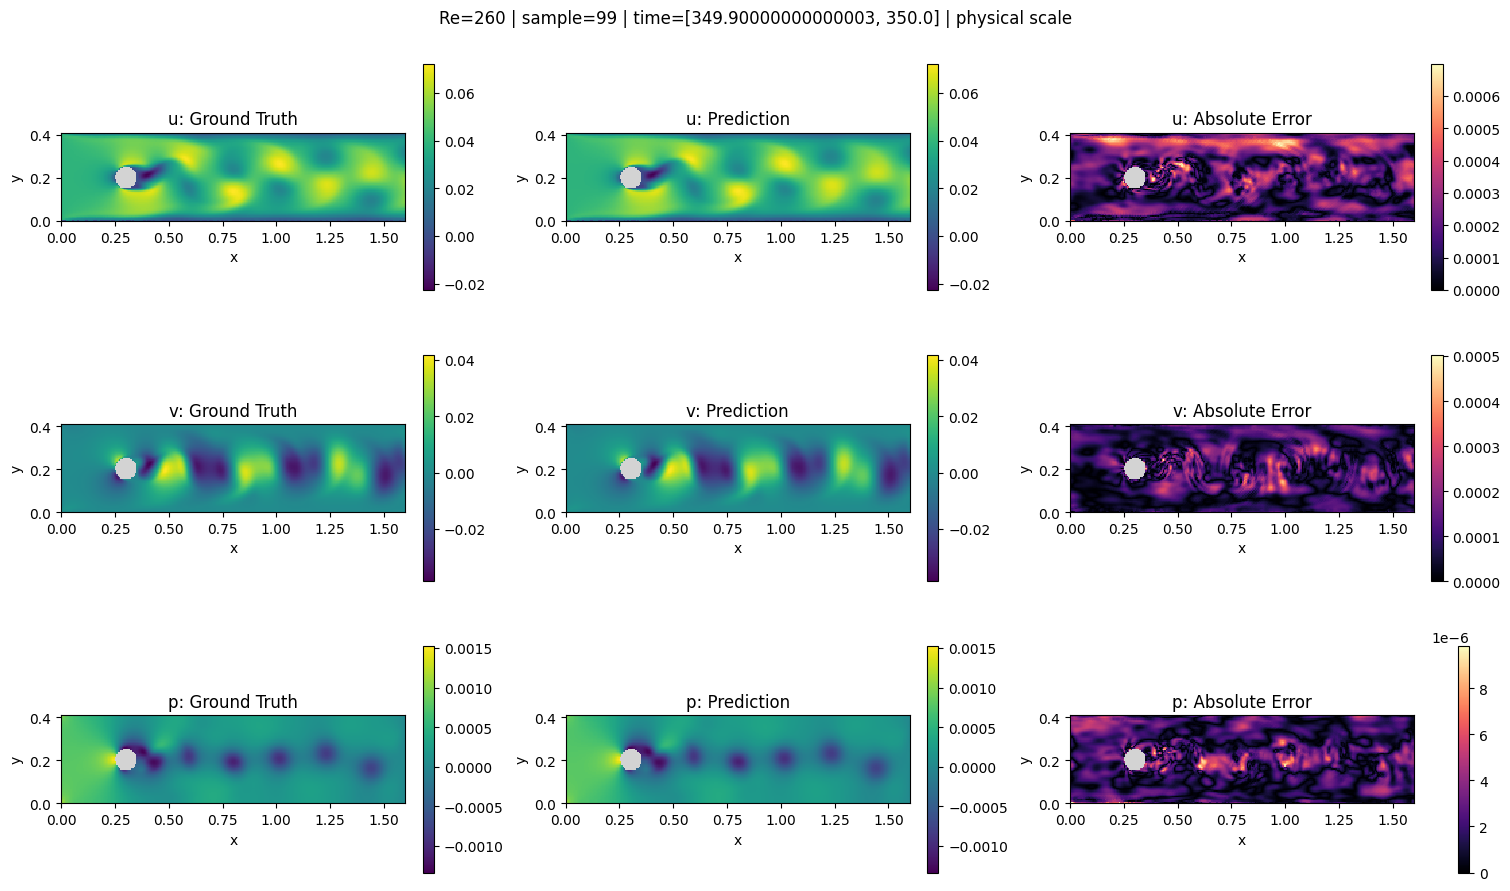

In [16]:
def plot_one_step_fields(result, sample_index, save_directory=None):
    prediction = result["prediction"][sample_index].numpy()
    target = result["ground_truth"][sample_index].numpy()
    valid = result["mask"][sample_index].numpy().astype(bool)
    channels = result["meta"]["output_channels"]
    bounds = result["meta"].get("bounds")
    fig, axes = plt.subplots(len(channels), 3, figsize=(15, 3 * len(channels)),
                             squeeze=False, constrained_layout=True)
    for row, channel in enumerate(channels):
        lo = min(target[row][valid].min(), prediction[row][valid].min())
        hi = max(target[row][valid].max(), prediction[row][valid].max())
        if lo == hi:
            padding = max(abs(float(lo)) * 0.01, 1e-8)
            lo, hi = lo - padding, hi + padding
        error = np.abs(prediction[row] - target[row])
        fields = (target[row], prediction[row], error)
        for col, (title, values) in enumerate(zip(("Ground Truth", "Prediction", "Absolute Error"), fields)):
            axis = axes[row, col]
            cmap = plt.get_cmap("magma" if col == 2 else "viridis").copy()
            cmap.set_bad("lightgray")
            im = axis.imshow(np.ma.array(values, mask=~valid), origin="lower",
                             extent=bounds, aspect="equal", interpolation="nearest", cmap=cmap,
                             vmin=0 if col == 2 else lo,
                             vmax=max(float(error[valid].max()), 1e-12) if col == 2 else hi)
            axis.set_title(f"{channel}: {title}")
            axis.set_xlabel("x" if bounds is not None else "grid column")
            axis.set_ylabel("y" if bounds is not None else "grid row")
            fig.colorbar(im, ax=axis, shrink=0.8)
    time_label = ""
    if result.get("times") is not None:
        time_label = f" | time={torch.as_tensor(result['times'][sample_index]).tolist()}"
    fig.suptitle(f"Re={result['Re']:g} | sample={sample_index}{time_label} | physical scale")
    if save_directory is not None:
        save_directory.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_directory / f"Re{result['Re']:g}_sample{sample_index:04d}_fields.png", dpi=150)
    plt.show()
    plt.close(fig)

# 保存結果を後日再表示する場合:
# field_result = torch.load(field_result_path, map_location="cpu", weights_only=False)
valid = field_result["mask"].unsqueeze(1)
error = (field_result["prediction"].double() - field_result["ground_truth"].double()).masked_fill(~valid, 0)
truth = field_result["ground_truth"].double().masked_fill(~valid, 0)
error_energy = error.square().sum((1, 2, 3))
truth_energy = truth.square().sum((1, 2, 3))
relative_l2 = torch.full_like(truth_energy, float("nan"))
nonzero = truth_energy > 0
relative_l2[nonzero] = (error_energy[nonzero] / truth_energy[nonzero]).sqrt()
count = len(relative_l2)
if N_REPRESENTATIVE < 1:
    raise ValueError("N_REPRESENTATIVE must be positive")
representatives = np.linspace(0, count - 1, min(N_REPRESENTATIVE, count)).round().astype(int).tolist()
if nonzero.any():
    worst = int(relative_l2.nan_to_num(nan=-1).argmax())
    representatives = sorted(set(representatives + [worst]))
    print(f"Maximum physical/valid-region Relative L2: sample={worst}, error={relative_l2[worst]:.6g}")
if not nonzero.all():
    print("正解のノルムが0のサンプルはRelative L2未定義のため最大点の選択から除外します。")
print("Visualization samples:", representatives)
plot_directory = result_dir / "plots" / f"Re{field_result['Re']:g}" if SAVE_FIELD_PNG else None
for sample_index in representatives:
    plot_one_step_fields(field_result, sample_index, plot_directory)

# 任意の時刻を表示する場合:
# plot_one_step_fields(field_result, sample_index=0)
